# StreamFlix — Phase 2: Exploratory Data Analysis (EDA)
**Analyst:** Vaishali Sandipsing Girase

**Goal:** Understand patterns in viewing, content, subscribers and reviews through 10 charts, each followed by a short observation. All charts are also saved as PNG files in a `charts/` folder.

**Note from Phase 1:** about 20% of sessions are dated after the subscriber's churn date. For EDA we use **all sessions** (they are real rows in the data); this is revisited in Phase 3.

## 0. Setup — load data and prepare columns

In [13]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('charts', exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.labelsize': 11})
BLUE, ORANGE, GREY, GREEN, RED = '#2E6FBA', '#F28E2B', '#B8C2CC', '#4CA66B', '#D9534F'

sub = pd.read_csv('subscribers.csv', parse_dates=['signup_date', 'churn_date'])
tit = pd.read_csv('titles.csv')
wh  = pd.read_csv('watch_history.csv', parse_dates=['watch_date'])
rev = pd.read_csv('reviews.csv')

# helper columns
wh['hours'] = wh.watch_duration_min / 60
age_bins   = [12, 17, 24, 34, 44, 54, 64, 100]
age_labels = ['13-17', '18-24', '25-34', '35-44', '45-54', '55-64', '65+']
sub['age_group'] = pd.cut(sub.age, bins=age_bins, labels=age_labels)

# join sessions with title and subscriber details
wh = (wh.merge(tit[['title_id', 'primary_genre', 'type']], on='title_id', how='left')
        .merge(sub[['subscriber_id', 'country', 'plan_type', 'age', 'age_group']], on='subscriber_id', how='left'))

print('Sessions:', f'{len(wh):,}', '| Total watch hours:', f'{wh.hours.sum():,.0f}')
print('Data covers', wh.watch_date.min().date(), 'to', wh.watch_date.max().date())

Sessions: 650,000 | Total watch hours: 3,333,468
Data covers 2017-03-10 to 2026-05-31


## Chart 1 — Monthly viewing volume (sessions per month)

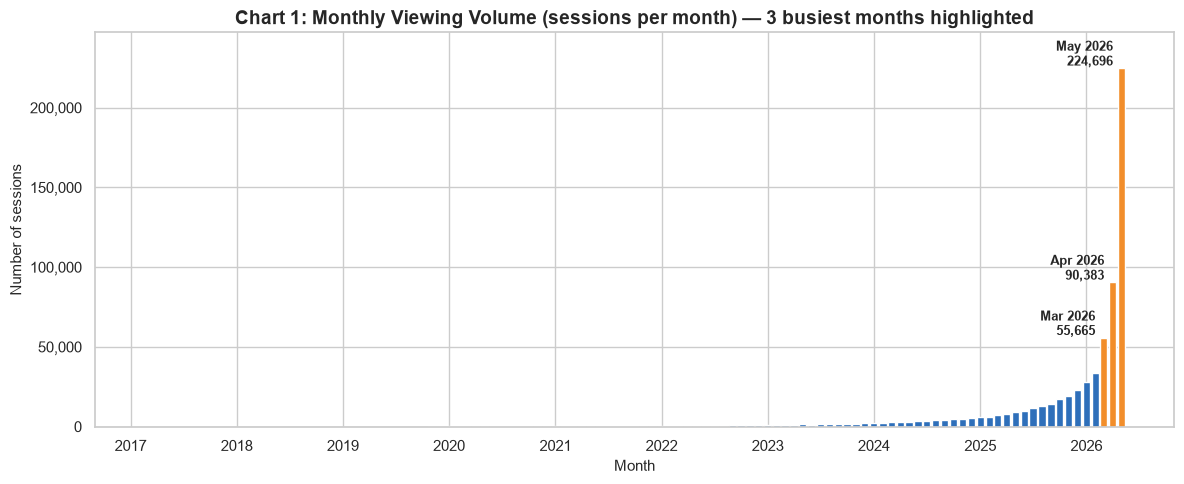

Top 3 months share of all sessions: 57.0 %
Share of sessions in Jan-May 2026  : 66.5 %


In [14]:
monthly = wh.groupby(wh.watch_date.dt.to_period('M')).size()
monthly = monthly.reindex(pd.period_range(monthly.index.min(), monthly.index.max(), freq='M'), fill_value=0)
top3 = monthly.nlargest(3).index
colors = [ORANGE if p in top3 else BLUE for p in monthly.index]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(monthly.index.to_timestamp(), monthly.values, width=25, color=colors)
for p in top3:
    ax.annotate(f"{p.strftime('%b %Y')}\n{monthly[p]:,}", (p.to_timestamp(), monthly[p]),
                textcoords='offset points', xytext=(-6, 2), ha='right', fontsize=9, fontweight='bold')
ax.set_title('Chart 1: Monthly Viewing Volume (sessions per month) — 3 busiest months highlighted')
ax.set_xlabel('Month'); ax.set_ylabel('Number of sessions')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_ylim(0, monthly.max() * 1.1)
plt.tight_layout(); plt.savefig('charts/01_monthly_sessions.png', dpi=150); plt.show()

print('Top 3 months share of all sessions:', round(monthly.nlargest(3).sum() / monthly.sum() * 100, 1), '%')
print('Share of sessions in Jan-May 2026  :', round((wh.watch_date >= '2026-01-01').mean() * 100, 1), '%')

**Observation:** Viewing has grown explosively, from only a handful of sessions per month in 2017–2018 to **224,696 sessions in May 2026**. The three busiest months are May 2026 (224,696), April 2026 (90,383) and March 2026 (55,665), which together hold **57% of all sessions**, and 66.5% of all sessions happen in just the first five months of 2026. May 2026 is 149% higher than April 2026, a jump this large should be confirmed with the data team (real growth or a logging effect?) before it is presented as a fact.

## Chart 2 — Monthly watch hours trend and year-over-year comparison

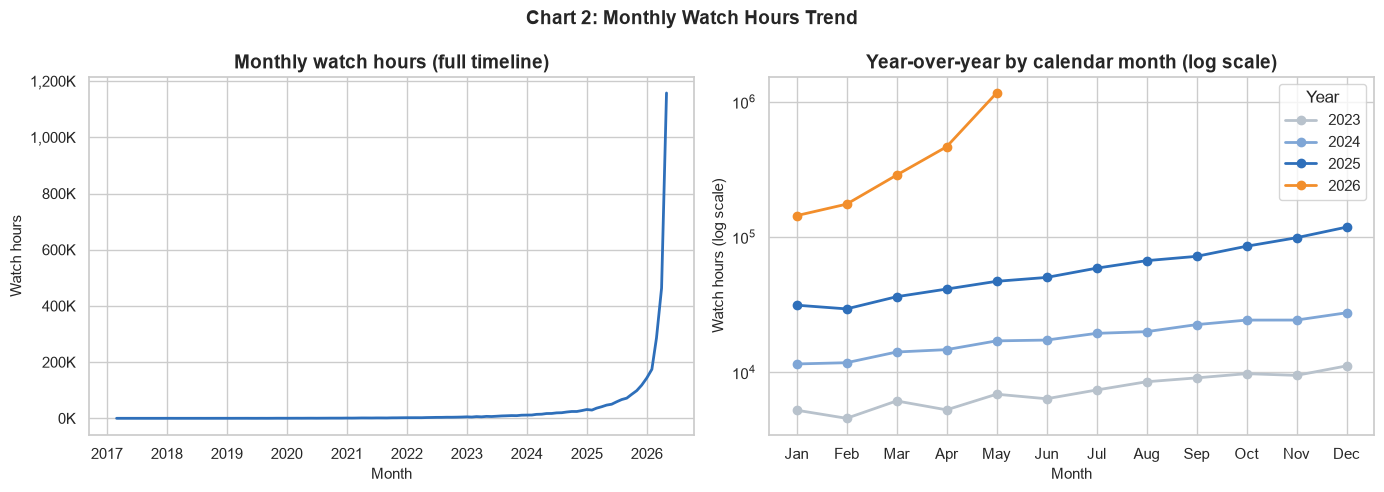

Full-year hours: {2023: 89666.0, 2024: 223994.0, 2025: 733939.0}
Growth 2024 vs 2023: 149.8 % | 2025 vs 2024: 227.7 %
Jan-May hours -> 2025: 184783 | 2026: 2225299 | growth: 1104.3 %


In [15]:
mh = wh.groupby(wh.watch_date.dt.to_period('M')).hours.sum()
pv = (wh.assign(year=wh.watch_date.dt.year, month=wh.watch_date.dt.month)
        .pivot_table(index='month', columns='year', values='hours', aggfunc='sum'))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
a1.plot(mh.index.to_timestamp(), mh.values, color=BLUE, lw=2)
a1.set_title('Monthly watch hours (full timeline)')
a1.set_xlabel('Month'); a1.set_ylabel('Watch hours')
a1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:,.0f}K'))

for y, c in zip([2023, 2024, 2025, 2026], [GREY, '#7FA6D6', BLUE, ORANGE]):
    a2.plot(pv.index, pv[y], marker='o', color=c, lw=2, label=str(y))
a2.set_yscale('log')
a2.set_xticks(range(1, 13)); a2.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
a2.set_title('Year-over-year by calendar month (log scale)')
a2.set_xlabel('Month'); a2.set_ylabel('Watch hours (log scale)'); a2.legend(title='Year')
fig.suptitle('Chart 2: Monthly Watch Hours Trend', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('charts/02_monthly_watch_hours.png', dpi=150); plt.show()

fy = wh.groupby(wh.watch_date.dt.year).hours.sum()
jm = wh[wh.watch_date.dt.month <= 5].groupby(wh.watch_date.dt.year).hours.sum()
print('Full-year hours:', fy.loc[2023:2025].round(0).to_dict())
print('Growth 2024 vs 2023:', round((fy[2024] / fy[2023] - 1) * 100, 1), '% | 2025 vs 2024:', round((fy[2025] / fy[2024] - 1) * 100, 1), '%')
print('Jan-May hours -> 2025:', round(jm[2025]), '| 2026:', round(jm[2026]), '| growth:', round((jm[2026] / jm[2025] - 1) * 100, 1), '%')

**Observation:** Watch hours follow the same steep curve as sessions. Full-year hours grew from about 89.7K in 2023 to 224K in 2024 (+150%) and 734K in 2025 (+228%). 2026 has only 5 months of data, so it must be compared like-for-like: Jan–May 2026 has 2.23M hours versus 185K in Jan–May 2025. Within each of 2023–2025, hours rise from January to December (e.g. 31K in Jan 2025 to 118K in Dec 2025), but because the platform is growing so fast we cannot separate a true seasonal pattern from plain growth. Phase 3 should adjust for growth before claiming seasonality.

## Chart 3 — Genre-wise watch-hours share

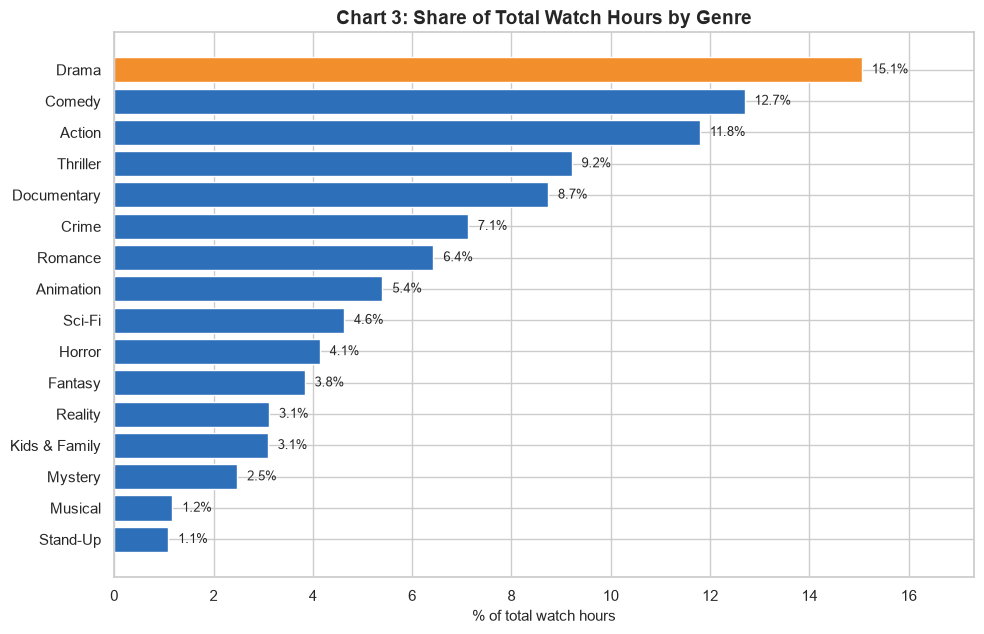

Top 3 genres share: 39.5 % | Top 5: 57.5 %
{'Drama': 501884.0, 'Comedy': 423149.0, 'Action': 393172.0}


In [16]:
g = wh.groupby('primary_genre').hours.sum().sort_values()
share = g / g.sum() * 100
colors = [ORANGE if v == share.max() else BLUE for v in share.values]

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(share.index, share.values, color=colors)
for i, v in enumerate(share.values):
    ax.text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set_title('Chart 3: Share of Total Watch Hours by Genre')
ax.set_xlabel('% of total watch hours'); ax.set_ylabel('')
ax.set_xlim(0, share.max() * 1.15)
plt.tight_layout(); plt.savefig('charts/03_genre_hours_share.png', dpi=150); plt.show()

print('Top 3 genres share:', round(share.nlargest(3).sum(), 1), '% | Top 5:', round(share.nlargest(5).sum(), 1), '%')
print(g.sort_values(ascending=False).round(0).head(3).to_dict())

**Observation:** **Drama earns the most watch time** (15.1%, about 502K hours), followed by Comedy (12.7%) and Action (11.8%). The top 3 genres make up 39.5% of all hours and the top 5 make up 57.5%. The smallest genres are Stand-Up (1.1%) and Musical (1.2%), so they contribute very little watch time. Whether they are *under-performing* depends on what they cost, which we check in Phase 3 (hours per $1K spend).

## Chart 4 — Content type split (Movies vs TV Shows)

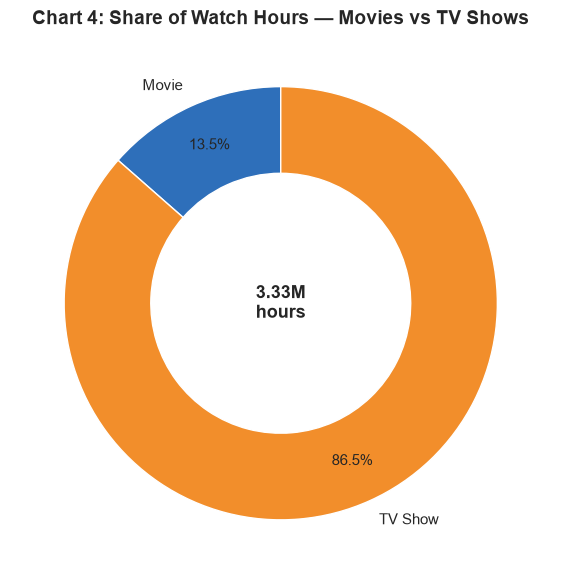

         sessions         hours  session_share_%  avg_hours_per_session
type                                                                   
Movie      382330  4.508588e+05             58.8                   1.18
TV Show    267670  2.882609e+06             41.2                  10.77


In [17]:
t = wh.groupby('type').hours.sum()
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.pie(t, labels=t.index, autopct='%1.1f%%', startangle=90, colors=[BLUE, ORANGE],
       wedgeprops=dict(width=0.4, edgecolor='white'), pctdistance=0.8, textprops={'fontsize': 11})
ax.text(0, 0, f'{t.sum() / 1e6:.2f}M\nhours', ha='center', va='center', fontsize=13, fontweight='bold')
ax.set_title('Chart 4: Share of Watch Hours — Movies vs TV Shows')
plt.tight_layout(); plt.savefig('charts/04_content_type_split.png', dpi=150); plt.show()

x = wh.groupby('type').agg(sessions=('watch_id', 'count'), hours=('hours', 'sum'))
x['session_share_%'] = (x.sessions / x.sessions.sum() * 100).round(1)
x['avg_hours_per_session'] = (x.hours / x.sessions).round(2)
print(x)

**Observation:** **TV Shows generate 86.5% of all watch hours**, even though they account for only 41% of sessions. Movies are 59% of sessions but just 13.5% of hours. The reason is session length: an average TV Show session is about 10.8 hours versus 1.2 hours for a movie, because series run across many episodes and seasons. This means TV Shows are the main engine of watch time on the platform.

## Chart 5 — Top 10 countries by watch hours

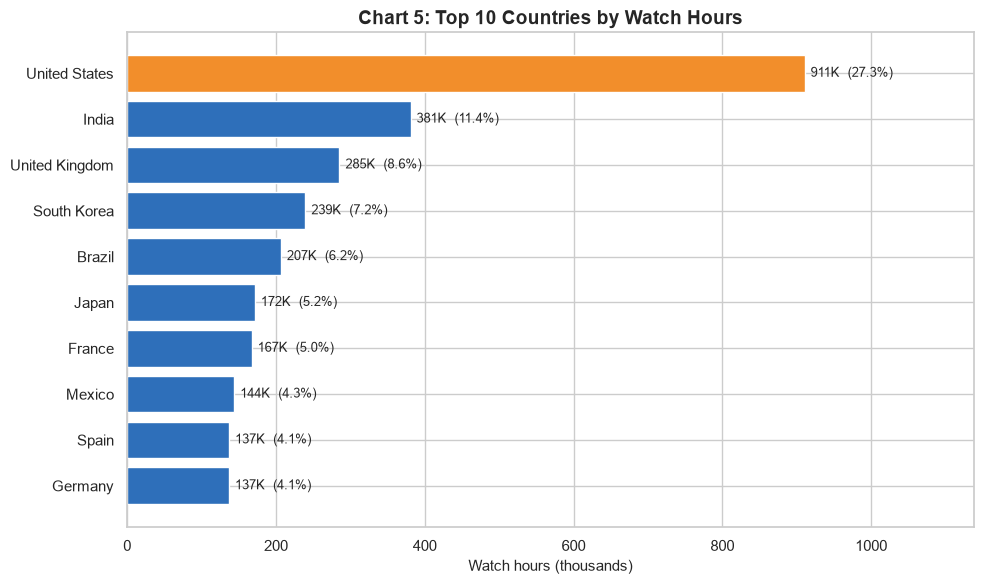

Top 10 countries share of all hours: 83.4 %
US + India share: 38.7 %
Subscribers per country (top 5): {'United States': 3774, 'India': 1873, 'United Kingdom': 1267, 'South Korea': 1096, 'Japan': 842}


In [18]:
c = wh.groupby('country').hours.sum().nlargest(10).sort_values()
total = wh.hours.sum()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(c.index, c.values / 1000, color=[ORANGE if v == c.max() else BLUE for v in c.values])
for i, v in enumerate(c.values):
    ax.text(v / 1000 + 8, i, f'{v/1000:,.0f}K  ({v/total*100:.1f}%)', va='center', fontsize=9)
ax.set_title('Chart 5: Top 10 Countries by Watch Hours')
ax.set_xlabel('Watch hours (thousands)'); ax.set_ylabel('')
ax.set_xlim(0, c.max() / 1000 * 1.25)
plt.tight_layout(); plt.savefig('charts/05_top10_countries.png', dpi=150); plt.show()

print('Top 10 countries share of all hours:', round(c.sum() / total * 100, 1), '%')
print('US + India share:', round((c['United States'] + c['India']) / total * 100, 1), '%')
print('Subscribers per country (top 5):', sub.country.value_counts().head(5).to_dict())

**Observation:** The **United States leads with about 911K hours (27.3% of the total)**, followed by India (381K), the United Kingdom (285K), South Korea (239K) and Brazil (207K). The top 10 countries together account for 83.4% of all watch hours, and the US and India alone make up 38.7%. The ranking closely follows subscriber counts (US 3,774 subscribers, India 1,873), so market size, not unusually heavy viewing, explains most of the difference.

## Chart 6 — Subscriber plan distribution

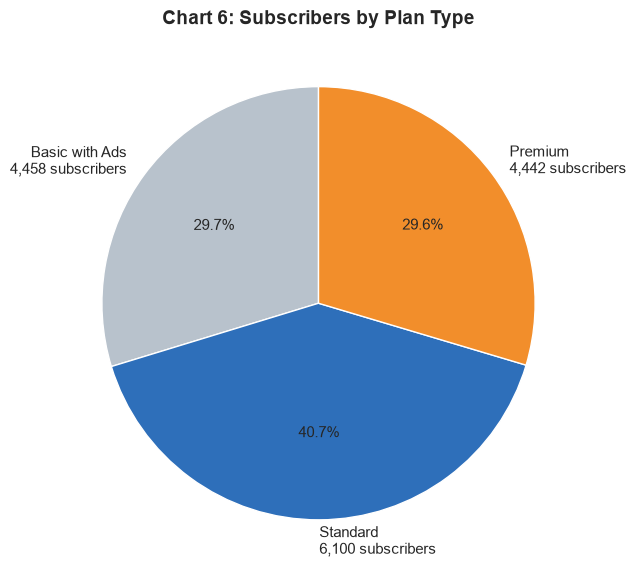

{'Basic with Ads': 4458, 'Standard': 6100, 'Premium': 4442}


In [19]:
p = sub.plan_type.value_counts().reindex(['Basic with Ads', 'Standard', 'Premium'])
fig, ax = plt.subplots(figsize=(7, 6))
ax.pie(p, labels=[f'{n}\n{v:,} subscribers' for n, v in p.items()], autopct='%1.1f%%', startangle=90,
       colors=[GREY, BLUE, ORANGE], wedgeprops=dict(edgecolor='white'), textprops={'fontsize': 11})
ax.set_title('Chart 6: Subscribers by Plan Type')
plt.tight_layout(); plt.savefig('charts/06_plan_distribution.png', dpi=150); plt.show()
print(p.to_dict())

**Observation:** **Standard is the largest plan with 6,100 subscribers (40.7%)**, while Basic with Ads (4,458, 29.7%) and Premium (4,442, 29.6%) are almost identical in size. Since Premium costs more than three times as much as Basic ($22.99 vs $6.99), a Premium subscriber is worth far more revenue, so a plan with the same head-count can contribute very different income. We quantify this with MRR and ARPU in Phase 3.

## Chart 7 — Device usage

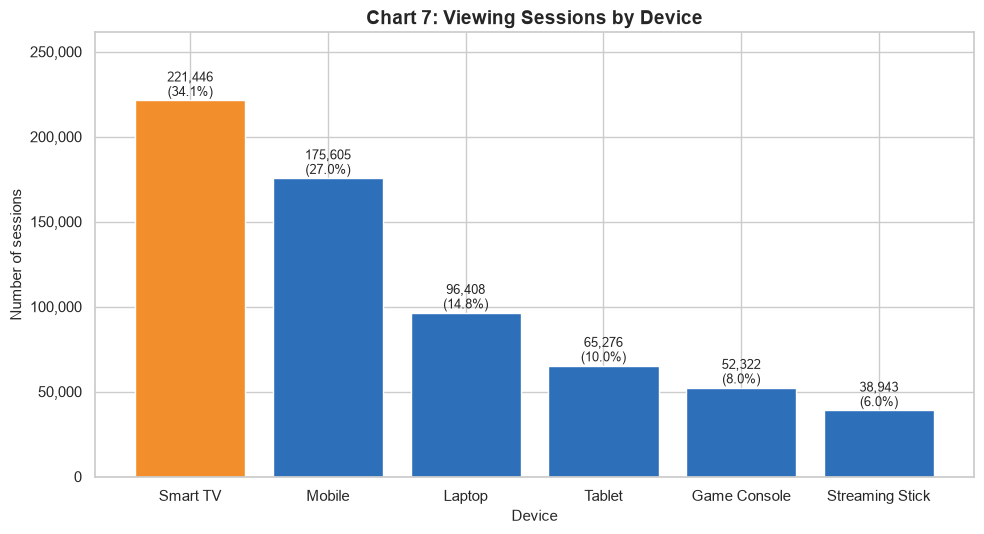

Share of hours by device (%): {'Smart TV': 34.0, 'Mobile': 27.0, 'Laptop': 14.9, 'Tablet': 9.9, 'Game Console': 8.1, 'Streaming Stick': 6.0}


In [20]:
d = wh.device.value_counts()
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(d.index, d.values, color=[ORANGE] + [BLUE] * (len(d) - 1))
for i, v in enumerate(d.values):
    ax.text(i, v + 2500, f'{v:,}\n({v/d.sum()*100:.1f}%)', ha='center', fontsize=9)
ax.set_title('Chart 7: Viewing Sessions by Device')
ax.set_xlabel('Device'); ax.set_ylabel('Number of sessions')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_ylim(0, d.max() * 1.18)
plt.tight_layout(); plt.savefig('charts/07_device_usage.png', dpi=150); plt.show()

h = wh.groupby('device').hours.sum()
print('Share of hours by device (%):', (h / h.sum() * 100).round(1).sort_values(ascending=False).to_dict())

**Observation:** **Smart TV is the most used device (34.1% of sessions)**, followed by Mobile (27.0%), Laptop (14.8%), Tablet (10.0%), Game Console (8.0%) and Streaming Stick (6.0%). Smart TV and Mobile together carry 61% of all viewing. The share of watch *hours* by device is almost identical to the share of sessions, which means no device has noticeably longer or shorter sessions than the others.

## Chart 8 — Age distribution of subscribers

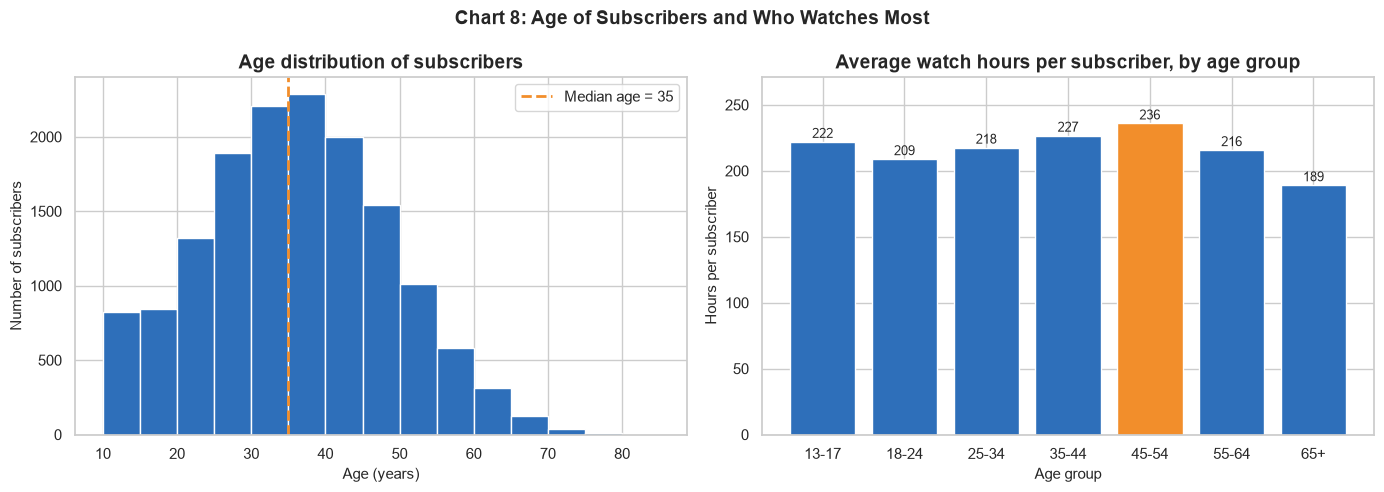

           subscribers  total_hours  hours_per_sub
age_group                                         
13-17             1270     281924.0          222.0
18-24             1715     358172.0          208.8
25-34             4094     890783.0          217.6
35-44             4291     972657.0          226.7
45-54             2557     603302.0          235.9
55-64              892     192413.0          215.7
65+                181      34216.0          189.0
Share of subscribers aged 25-44: 55.9 %


In [21]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
a1.hist(sub.age, bins=range(10, 90, 5), color=BLUE, edgecolor='white')
a1.axvline(sub.age.median(), color=ORANGE, ls='--', lw=2, label=f'Median age = {sub.age.median():.0f}')
a1.set_title('Age distribution of subscribers'); a1.set_xlabel('Age (years)'); a1.set_ylabel('Number of subscribers'); a1.legend()

hrs = wh.groupby('age_group', observed=True).hours.sum()
subs_by_age = sub.age_group.value_counts()
hps = (hrs / subs_by_age).reindex(age_labels)
bars = a2.bar(hps.index, hps.values, color=[ORANGE if v == hps.max() else BLUE for v in hps.values])
for i, v in enumerate(hps.values):
    a2.text(i, v + 3, f'{v:,.0f}', ha='center', fontsize=9)
a2.set_title('Average watch hours per subscriber, by age group'); a2.set_xlabel('Age group'); a2.set_ylabel('Hours per subscriber')
a2.set_ylim(0, hps.max() * 1.15)
fig.suptitle('Chart 8: Age of Subscribers and Who Watches Most', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('charts/08_age_distribution.png', dpi=150); plt.show()

out = pd.DataFrame({'subscribers': subs_by_age.reindex(age_labels), 'total_hours': hrs.reindex(age_labels).round(0), 'hours_per_sub': hps.round(1)})
print(out)
print('Share of subscribers aged 25-44:', round(sub.age.between(25, 44).mean() * 100, 1), '%')

**Observation:** Most subscribers are in their late 20s to 40s: ages 25–44 make up **55.9% of the base** and the median age is 35. In total hours, the **35–44 group watches the most (about 973K hours)**, followed by 25–34 (891K), but this mainly reflects that these are the largest groups. Per subscriber, the 45–54 group is the most engaged (about 236 hours each) and the 65+ group the least (189 hours); the spread across age groups is fairly small.

## Chart 9 — Completion rate by genre

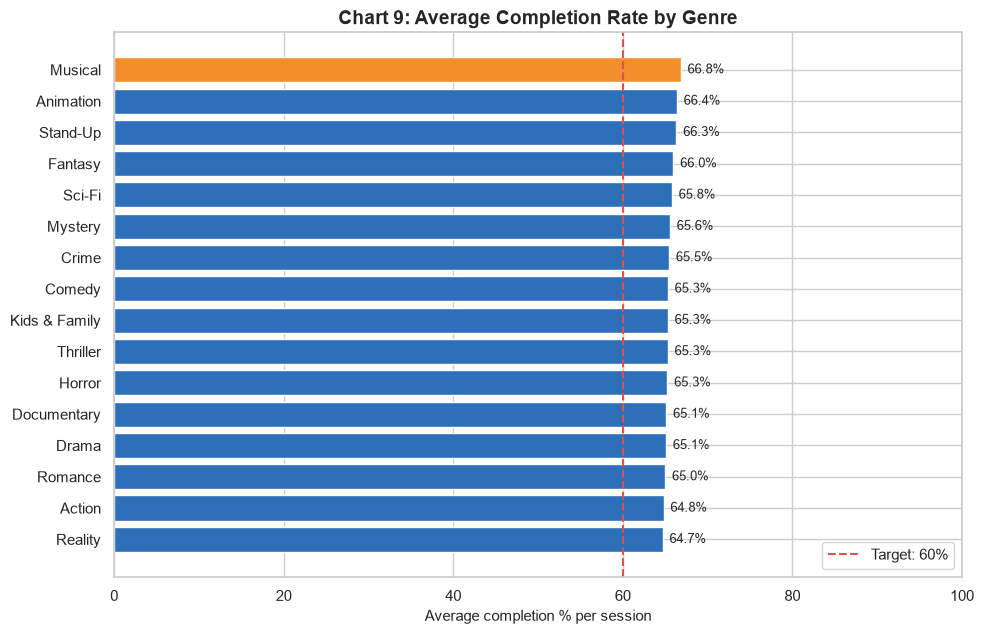

Overall average completion: 65.3 %
Genre range: Reality 64.7 - Musical 66.8
Sessions that passed the 90% "completed" threshold: 15.3 %


In [22]:
comp = wh.groupby('primary_genre').completion_pct.mean().sort_values()
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(comp.index, comp.values, color=[ORANGE if v == comp.max() else BLUE for v in comp.values])
ax.axvline(60, color=RED, ls='--', lw=1.5, label='Target: 60%')
for i, v in enumerate(comp.values):
    ax.text(v + 0.8, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set_xlim(0, 100)
ax.set_title('Chart 9: Average Completion Rate by Genre')
ax.set_xlabel('Average completion % per session'); ax.set_ylabel(''); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig('charts/09_completion_by_genre.png', dpi=150); plt.show()

print('Overall average completion:', round(wh.completion_pct.mean(), 1), '%')
print('Genre range:', comp.idxmin(), round(comp.min(), 1), '-', comp.idxmax(), round(comp.max(), 1))
print('Sessions that passed the 90% "completed" threshold:', round(wh.completed.mean() * 100, 1), '%')

**Observation:** The average completion rate is **65.3%, above the 60% target**, and it is remarkably similar across genres: from 64.7% (Reality) up to 66.8% (Musical), a spread of only about 2 points. Musical, Animation and Stand-Up are finished slightly more often, while Reality and Action slightly less, but these gaps are too small to guide decisions on their own. Note that only 15.3% of sessions pass the strict 90% "completed" flag, so how "finished" is defined changes the picture a lot.

## Chart 10 — Review sentiment breakdown

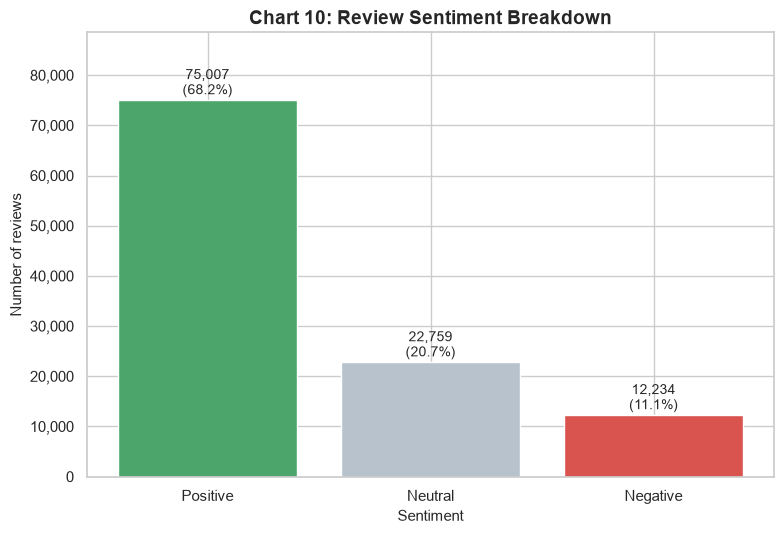

{'Positive': 75007, 'Neutral': 22759, 'Negative': 12234} | Positive : Negative ratio = 6.1 : 1


In [23]:
s = rev.sentiment.value_counts().reindex(['Positive', 'Neutral', 'Negative'])
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.bar(s.index, s.values, color=[GREEN, GREY, RED])
for i, v in enumerate(s.values):
    ax.text(i, v + 1200, f'{v:,}\n({v/s.sum()*100:.1f}%)', ha='center', fontsize=10)
ax.set_title('Chart 10: Review Sentiment Breakdown')
ax.set_xlabel('Sentiment'); ax.set_ylabel('Number of reviews')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_ylim(0, s.max() * 1.18)
plt.tight_layout(); plt.savefig('charts/10_review_sentiment.png', dpi=150); plt.show()
print(s.to_dict(), '| Positive : Negative ratio =', round(s['Positive'] / s['Negative'], 1), ': 1')

**Observation:** Reviews are strongly positive: **68.2% Positive (75,007)**, 20.7% Neutral (22,759) and only 11.1% Negative (12,234). Positive reviews outnumber negative ones by about 6 to 1. Overall audience sentiment is healthy; a useful follow-up is checking which genres or titles collect the most negative reviews.

## Summary — what Phase 2 tells us

In [24]:
print('Saved charts:')
for f in sorted(os.listdir('charts')):
    print(' -', f)

Saved charts:
 - 01_monthly_sessions.png
 - 02_monthly_watch_hours.png
 - 03_genre_hours_share.png
 - 04_content_type_split.png
 - 05_top10_countries.png
 - 06_plan_distribution.png
 - 07_device_usage.png
 - 08_age_distribution.png
 - 09_completion_by_genre.png
 - 10_review_sentiment.png


| Leadership question | What the charts suggest |
|---|---|
| Which genres drive watch time? | Drama (15.1%), Comedy (12.7%) and Action (11.8%) lead; Stand-Up and Musical are smallest. TV Shows give 86.5% of hours. |
| Who are the most engaged segments? | Core base is age 25–44 on the Standard plan; per-person engagement is highest at ages 45–54. |
| Seasonality? | Hours rise through each year (Dec highest), but strong platform growth hides the true seasonal effect. Needs adjusting in Phase 3. |
| Biggest markets? | US (27.3% of hours), India, UK, South Korea, Brazil; top 10 countries = 83.4% of hours. |
| Experience? | Smart TV and Mobile carry 61% of sessions; 68.2% of reviews are positive; average completion 65.3%. |

**Caveats to carry forward:** (1) viewing volume is heavily concentrated in 2026 (66.5% of sessions in 5 months), (2) about 20% of sessions fall after the subscriber's churn date (Phase 1), and (3) 2026 is a partial year (to 31 May), so always compare like-for-like periods.

**Next:** Phase 3 — the 10 business KPIs (churn, MRR, ARPU, hit concentration, Originals share, and more).